# Machine Learning Fundamentals: Model Evaluation & Feature Engineering


**Part 1 — Model Evaluation**


**Part 2 — Feature Engineering & Preprocessing**
-

In [1]:
# Core imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, KFold
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay,
    precision_score, recall_score, f1_score, classification_report,
    roc_curve, roc_auc_score, RocCurveDisplay
)

sns.set_style("whitegrid")
%matplotlib inline
np.random.seed(42)


---
# Part 1: Model Evaluation

## 1.1 Load the dataset

We use `load_breast_cancer` from scikit-learn: 30 numeric features describing cell nuclei, and a binary target (`0 = malignant`, `1 = benign`).


In [2]:
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name="target")

print("Feature matrix shape:", X.shape)
print("Target distribution:\n", y.value_counts())
X.head()


Feature matrix shape: (569, 30)
Target distribution:
 target
1    357
0    212
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## 1.2 Train/Test Split

We hold out a portion of the data (commonly 20-30%) purely for final evaluation. The model never sees this data during training. `stratify=y` keeps the class balance the same in both splits — important for imbalanced classification problems.


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y          # preserves class proportions in train & test
)

print(f"Train size: {X_train.shape[0]} samples")
print(f"Test size:  {X_test.shape[0]} samples")
print("\nTrain class balance:\n", y_train.value_counts(normalize=True))
print("\nTest class balance:\n", y_test.value_counts(normalize=True))


Train size: 455 samples
Test size:  114 samples

Train class balance:
 target
1    0.626374
0    0.373626
Name: proportion, dtype: float64

Test class balance:
 target
1    0.631579
0    0.368421
Name: proportion, dtype: float64


## 1.3 Baseline model

We'll fit a simple `LogisticRegression` (with scaling, since it's a distance/gradient-based model — see Part 2 for why scaling matters).


In [4]:
pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=5000, random_state=42))
])

pipe.fit(X_train, y_train)
y_pred = pipe.predict(X_test)
y_proba = pipe.predict_proba(X_test)[:, 1]   # probability of class "1"

print("Test accuracy:", pipe.score(X_test, y_test))


Test accuracy: 0.9824561403508771


## 1.4 Cross-Validation

A single train/test split gives one noisy estimate of performance. **K-fold cross-validation** trains and evaluates the model K times on different folds of the training data, giving a more robust estimate and a sense of variance.

`StratifiedKFold` is preferred for classification because it preserves class ratios in every fold.


In [5]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="accuracy")

print("Fold accuracies:", np.round(cv_scores, 4))
print(f"Mean CV accuracy: {cv_scores.mean():.4f}  (+/- {cv_scores.std():.4f})")


Fold accuracies: [0.967 0.989 0.978 0.989 0.967]
Mean CV accuracy: 0.9780  (+/- 0.0098)


In [6]:
# You can cross-validate on other metrics too
for metric in ["precision", "recall", "f1", "roc_auc"]:
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring=metric)
    print(f"{metric:10s}: mean={scores.mean():.4f}  std={scores.std():.4f}")


precision : mean=0.9795  std=0.0162
recall    : mean=0.9860  std=0.0131
f1        : mean=0.9825  std=0.0078
roc_auc   : mean=0.9959  std=0.0050


## 1.5 Confusion Matrix

The confusion matrix breaks predictions down into:

|                | Predicted Negative | Predicted Positive |
|----------------|--------------------|---------------------|
| **Actual Negative** | True Negative (TN) | False Positive (FP) |
| **Actual Positive** | False Negative (FN) | True Positive (TP) |

This is the foundation for precision, recall, and F1.


Confusion Matrix:
 [[41  1]
 [ 1 71]]


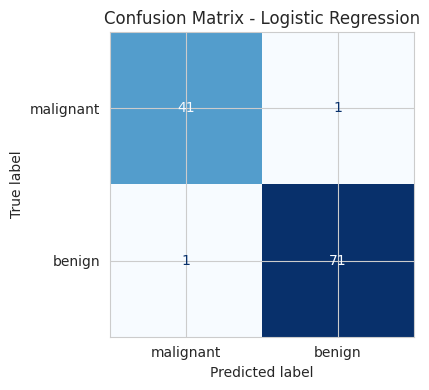

In [7]:
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:\n", cm)

fig, ax = plt.subplots(figsize=(5, 4))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=data.target_names)
disp.plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Confusion Matrix - Logistic Regression")
plt.tight_layout()
plt.show()


## 1.6 Precision, Recall, F1-score

- **Precision** = TP / (TP + FP) — of everything predicted positive, how much was correct? (Cost of false positives matters.)
- **Recall** (Sensitivity) = TP / (TP + FN) — of everything actually positive, how much did we catch? (Cost of false negatives matters.)
- **F1-score** = harmonic mean of precision and recall — a single number that balances both.

Which metric to prioritize depends on the problem: e.g. in medical screening, recall (catching all positives) is often prioritized over precision.


In [8]:
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

print("\nFull classification report:\n")
print(classification_report(y_test, y_pred, target_names=data.target_names))


Precision: 0.9861
Recall:    0.9861
F1-score:  0.9861

Full classification report:

              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



## 1.7 ROC Curve & AUC

The **ROC curve** plots True Positive Rate (recall) vs. False Positive Rate at every possible classification threshold. **AUC** (Area Under the Curve) summarizes this into one number:

- AUC = 1.0 → perfect classifier
- AUC = 0.5 → no better than random guessing

ROC-AUC is threshold-independent, which makes it useful for comparing models regardless of the cutoff you eventually choose.


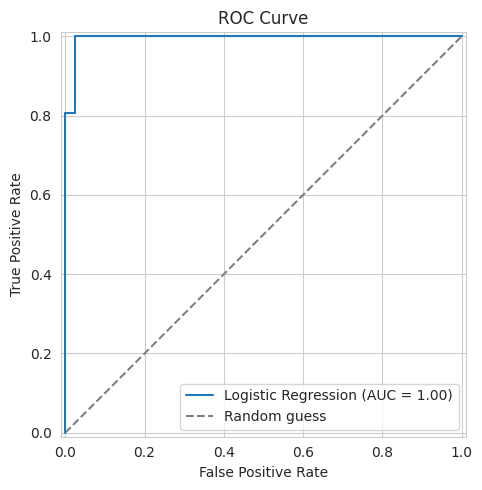

ROC-AUC: 0.9954


In [9]:
fpr, tpr, thresholds = roc_curve(y_test, y_proba)
auc = roc_auc_score(y_test, y_proba)

fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay(fpr=fpr, tpr=tpr, roc_auc=auc, estimator_name="Logistic Regression").plot(ax=ax)
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random guess")
ax.set_title("ROC Curve")
ax.legend()
plt.tight_layout()
plt.show()

print(f"ROC-AUC: {auc:.4f}")


### Quick recap — Part 1

| Concept | Purpose |
|---|---|
| Train/test split | Honest, held-out evaluation of a fitted model |
| Cross-validation | Robust performance estimate; reduces variance from a single split |
| Confusion matrix | Breaks down correct/incorrect predictions by class |
| Precision / Recall / F1 | Class-specific performance, especially for imbalanced data |
| ROC-AUC | Threshold-independent measure of separability between classes |


---
# Part 2: Feature Engineering, Scaling & Missing Data

To make this section realistic, we'll deliberately corrupt a copy of the dataset with **missing values** and add a couple of **engineered features**, then build a clean **preprocessing pipeline**.


## 2.1 Simulate a messier, real-world dataset

Real datasets rarely arrive clean. Let's randomly knock out ~8% of values in a few columns to simulate missing data (e.g. sensor dropout, unrecorded measurements, merge issues).


In [10]:
rng = np.random.default_rng(42)

X_messy = X.copy()

# Introduce missing values (MCAR - missing completely at random) into a few columns
cols_to_corrupt = ["mean radius", "mean texture", "mean smoothness", "worst area"]
for col in cols_to_corrupt:
    n_missing = int(0.08 * len(X_messy))
    missing_idx = rng.choice(X_messy.index, size=n_missing, replace=False)
    X_messy.loc[missing_idx, col] = np.nan

print("Missing values per column:\n")
print(X_messy.isna().sum()[X_messy.isna().sum() > 0])


Missing values per column:

mean radius        45
mean texture       45
mean smoothness    45
worst area         45
dtype: int64


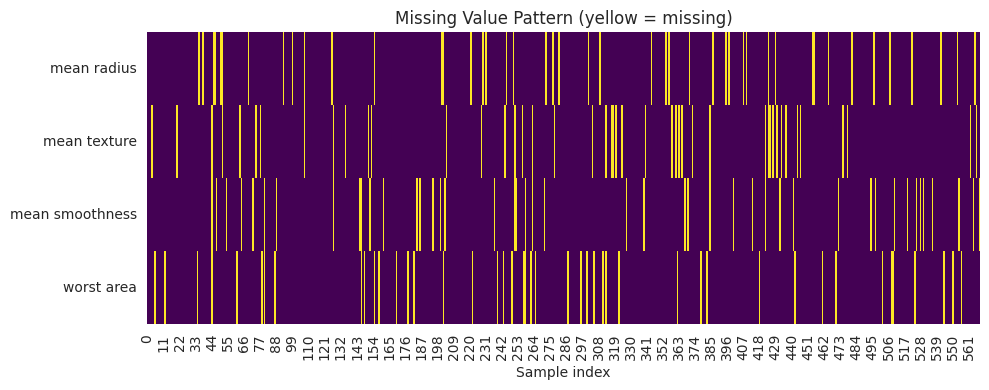

In [ ]:
# Visualize the pattern of missingness
plt.figure(figsize=(10, 4))
sns.heatmap(X_messy[cols_to_corrupt].isna().T, cbar=False, cmap="viridis")
plt.title("Missing Value Pattern (yellow = missing)")
plt.xlabel("Sample index")
plt.tight_layout()
plt.show()


## 2.2 Handling Missing Data

Common strategies:

1. **Drop rows/columns** — simplest, but wastes data (only fine if missingness is rare and MCAR).
2. **Mean/median imputation** — fast, works well for numeric features with no strong skew (median is more robust to outliers).
3. **Mode imputation** — for categorical features.
4. **Model-based imputation** (e.g. KNNImputer, IterativeImputer) — uses relationships between features, more accurate but more expensive.
5. **Add a "missingness indicator"** — sometimes *whether* a value is missing is itself informative.

We'll use median imputation here, and also add a missing-indicator flag.


In [11]:
# Option A: drop rows with any missing value (usually wasteful - shown for comparison)
dropped = X_messy.dropna()
print(f"Original rows: {len(X_messy)}  |  After dropna(): {len(dropped)}  "
      f"({len(X_messy) - len(dropped)} rows lost)")


Original rows: 569  |  After dropna(): 405  (164 rows lost)


In [12]:
# Option B (preferred): impute, with an added "was this missing?" indicator feature
imputer = SimpleImputer(strategy="median")

X_imputed = X_messy.copy()

# Add binary indicator columns BEFORE imputing, so we don't lose the "was missing" signal
for col in cols_to_corrupt:
    X_imputed[f"{col}_was_missing"] = X_messy[col].isna().astype(int)

X_imputed[X_messy.columns] = imputer.fit_transform(X_messy)

print("Missing values after imputation:", X_imputed[data.feature_names].isna().sum().sum())
X_imputed[["mean radius", "mean radius_was_missing"]].head()


Missing values after imputation: 0


,mean radius,mean radius_was_missing
0,17.99,0
1,20.57,0
2,19.69,0
3,11.42,0
4,20.29,0


## 2.3 Feature Engineering

Feature engineering means creating new, more informative features from the raw ones. This can meaningfully boost model performance even before touching the model itself. Examples here:

- **Ratio features** (e.g. area per unit radius) can capture relationships a linear model can't see directly.
- **Interaction features** (products of two related measurements).
- **Binning** a continuous variable into categories, when the relationship with the target is non-linear/thresholded.
- The **missingness indicators** we just created are also a form of feature engineering.


In [13]:
X_fe = X_imputed.copy()

# Ratio feature: how "dense" the worst-case area is relative to mean radius
X_fe["worst_area_to_mean_radius_ratio"] = X_fe["worst area"] / X_fe["mean radius"]

# Interaction feature: texture roughness scaled by smoothness
X_fe["texture_smoothness_interaction"] = X_fe["mean texture"] * X_fe["mean smoothness"]

# Binned feature: coarse category for tumor size
X_fe["mean_radius_bin"] = pd.cut(
    X_fe["mean radius"],
    bins=[0, 12, 15, 20, np.inf],
    labels=["small", "medium", "large", "very_large"]
)

X_fe[["mean radius", "worst area", "worst_area_to_mean_radius_ratio",
      "texture_smoothness_interaction", "mean_radius_bin"]].head()


,mean radius,worst area,worst_area_to_mean_radius_ratio,texture_smoothness_interaction,mean_radius_bin
0,17.99,2019.0,112.229016,1.228992,large
1,20.57,1956.0,95.089937,1.505830,very_large
2,19.69,1709.0,86.795328,2.329000,large
3,11.42,567.7,49.711033,2.688262,small
4,20.29,1575.0,77.624446,1.438302,very_large


In [14]:
# One-hot encode the new categorical bin so it can feed into a numeric model
X_fe_encoded = pd.get_dummies(X_fe, columns=["mean_radius_bin"], drop_first=True)
print("New shape after feature engineering:", X_fe_encoded.shape)
X_fe_encoded.columns.tolist()[-6:]   # show the newly added columns


New shape after feature engineering: (569, 39)


['worst area_was_missing',
 'worst_area_to_mean_radius_ratio',
 'texture_smoothness_interaction',
 'mean_radius_bin_medium',
 'mean_radius_bin_large',
 'mean_radius_bin_very_large']

## 2.4 Feature Scaling

Many algorithms (logistic regression, SVMs, KNN, k-means, PCA, neural nets) are sensitive to feature magnitude — a feature ranging 0–1000 will dominate one ranging 0–1 even if it's less predictive. Tree-based models (Random Forest, XGBoost) are scale-invariant and generally don't need this step.

Common scalers:

| Scaler | What it does | When to use |
|---|---|---|
| `StandardScaler` | mean = 0, std = 1 | Default choice; assumes roughly normal-ish data |
| `MinMaxScaler` | rescales to [0, 1] | When you need bounded ranges (e.g. neural nets, image data) |
| `RobustScaler` | uses median/IQR | Data with heavy outliers |

**Important:** always fit the scaler on the training data only, then transform both train and test — fitting on the full dataset leaks test-set information into training (**data leakage**).


In [ ]:
# Compare raw feature scales before scaling
print("Raw feature ranges (before scaling):")
print(X_fe_encoded[["mean radius", "mean area", "mean smoothness"]].describe().loc[["min", "max", "mean", "std"]])


Raw feature ranges (before scaling):
      mean radius    mean area  mean smoothness
min      6.981000   143.500000         0.062510
max     28.110000  2501.000000         0.163400
mean    14.096965   654.889104         0.096246
std      3.410401   351.914129         0.013330


In [19]:
# Correct workflow: split first, THEN fit scaler on train only
X_train_fe, X_test_fe, y_train_fe, y_test_fe = train_test_split(
    X_fe_encoded, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_fe)   # fit + transform on TRAIN
X_test_scaled = scaler.transform(X_test_fe)          # transform ONLY on TEST (no re-fitting!)

X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train_fe.columns, index=X_train_fe.index)

print("Scaled feature stats (train set) - mean should be ~0, std ~1:")
print(X_train_scaled[["mean radius", "mean area", "mean smoothness"]].describe().loc[["mean", "std"]])


Scaled feature stats (train set) - mean should be ~0, std ~1:
       mean radius     mean area  mean smoothness
mean -4.577535e-16 -1.717796e-16     1.112663e-16
std   1.001101e+00  1.001101e+00     1.001101e+00


### Quick recap — Part 2

| Concept | Purpose |
|---|---|
| Handling missing data | Imputation (mean/median/mode/model-based) or removal; consider adding a "missingness" indicator |
| Feature engineering | Ratios, interactions, binning — create features that expose signal to the model |
| Feature scaling | Puts features on comparable scales for distance/gradient-based algorithms; fit on train only |
| Pipeline / ColumnTransformer | Chains preprocessing + model so cross-validation and deployment stay leak-free and reproducible |

---
## Summary

This notebook walked through a full, realistic mini-workflow:
1. Split data properly (train/test, cross-validation)
2. Evaluate with the right metrics for the problem (confusion matrix, precision/recall/F1, ROC-AUC)
3. Clean and enrich the data (missing values, engineered features)
4. Scale features correctly, without leaking test information
5. Wrap it all in a single, reproducible `Pipeline`

These building blocks apply to almost any supervised learning project, regardless of the specific model used.
